# Typographic invariants: marks some models *never* use

Every model in this competition has formatting habits that come from its tokenizer, post-processing or style tuning. A few of them are **absolute in train**: across 150 passages per model, some models never produce a given mark, while others use it in hundreds of passages.

This notebook:

1. **mines** those negative invariants from `train.csv` with a simple significance test,
2. **checks them out of fold** (mine on 4 prompt folds, count violations on the 5th),
3. **measures** what they add on top of a plain classifier, out of fold,
4. gives a **drop-in function** that applies them to any ensemble's final logits and re-verifies every rule on train at run time.

Some of these rules (spaced em dash, curly apostrophe, curly opening quote for Claude/GLM) are already used by the top public notebooks; credit to the typography work in those notebooks (Roman Tamrazov, mercurydust and the stacks built on them). The others below are, as far as I know, not used yet.

Code and the rest of my experiments (grouped CV, embeddings, LoRA): [https://github.com/pedrohbenetton/kaggle-name-that-llm](https://github.com/pedrohbenetton/kaggle-name-that-llm) (MIT).

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for d in [os.environ.get("NTL_DATA", ""), "/kaggle/input/competitions/name-that-llm",
          "/kaggle/input/name-that-llm"]:
    if d and (Path(d) / "train.csv").exists():
        DATA = Path(d)
        break
train = pd.read_csv(DATA / "train.csv")
LABELS = sorted(train.model.unique())
N_PER_MODEL = train.model.value_counts()
print(train.shape, "|", len(LABELS), "models |", N_PER_MODEL.min(), "to", N_PER_MODEL.max(),
      "passages per model |", train.prompt_id.nunique(), "prompts")

(2699, 4) | 18 models | 149 to 150 passages per model | 150 prompts


## 1. Mining

Candidates: every non-alphanumeric character in train, plus a few multi-character patterns (spaced dashes, markdown). For a mark present in at least 25 passages, a model with **zero** passages containing it is a candidate invariant.

How surprising is a zero? If that model used the mark at the pooled rate *r* of the models that do use it, the chance of 0 hits in its 150 passages is **P0 = (1 − r)^150**. I keep a rule only if P0 < 1e-4 (about 100 candidates are tested, so this stays strict after a Bonferroni-style correction).

In [2]:
def candidates(texts):
    marks = {c for t in texts for c in t if not c.isalnum() and not c.isspace()}
    marks |= {" — ", " – ", " - ", "**", "\n\n", "\n- ", "...", "…", "--"}
    return sorted(marks)


def mine_rules(texts, labels, min_support=25, p_max=1e-4):
    texts, labels = pd.Series(list(texts)), pd.Series(list(labels))
    n = labels.value_counts()
    rules = []
    for m in candidates(texts):
        has = texts.str.contains(m, regex=False).to_numpy()
        if has.sum() < min_support:
            continue
        cnt = labels[has].value_counts().reindex(LABELS, fill_value=0)
        never = [l for l in LABELS if cnt[l] == 0]
        if not never:
            continue
        users = [l for l in LABELS if cnt[l] > 0]
        rate = cnt[users].sum() / n[users].sum()
        p0 = (1 - rate) ** int(n[never].min())
        if p0 < p_max:
            rules.append(dict(mark=m, support=int(has.sum()), rate=rate, p0=p0,
                              never=never, allowed=set(users)))
    return sorted(rules, key=lambda r: r["p0"])


RULES = mine_rules(train.text, train.model)
pd.DataFrame([{"mark": repr(r["mark"]), "passages with mark": r["support"],
               "rate in models that use it": f"{r['rate']:.1%}", "P0": f"{r['p0']:.0e}",
               "never used by": ", ".join(r["never"])} for r in RULES])

,mark,passages with mark,rate in models that use it,P0,never used by
0,'—',1052,46.8%,8e-42,"gemini-3.1-pro-preview, gemini-3.6-flash, gemi..."
1,'’',567,34.4%,6e-28,"claude-fable-5, claude-opus-4-6, claude-opus-4..."
2,"""'""",835,32.8%,1e-26,gpt-5.6-sol
3,' — ',86,14.3%,1e-10,"claude-fable-5, claude-opus-4-8, claude-sonnet..."
4,'“',93,7.8%,6e-06,"claude-fable-5, claude-opus-4-6, claude-opus-4..."
5,'”',93,7.8%,6e-06,"claude-fable-5, claude-opus-4-6, claude-opus-4..."
6,"'""'",109,6.1%,8e-05,"gemini-3.7-flash, gpt-5.6-luna, gpt-5.6-sol, g..."


A few of these are huge: the **em dash** (spaced or not) appears in ~40% of all passages, yet three Gemini models never use it; the **straight apostrophe** is in ~30% of passages and `gpt-5.6-sol` never uses it (it writes the curly one instead). Usage by model for the rule marks:

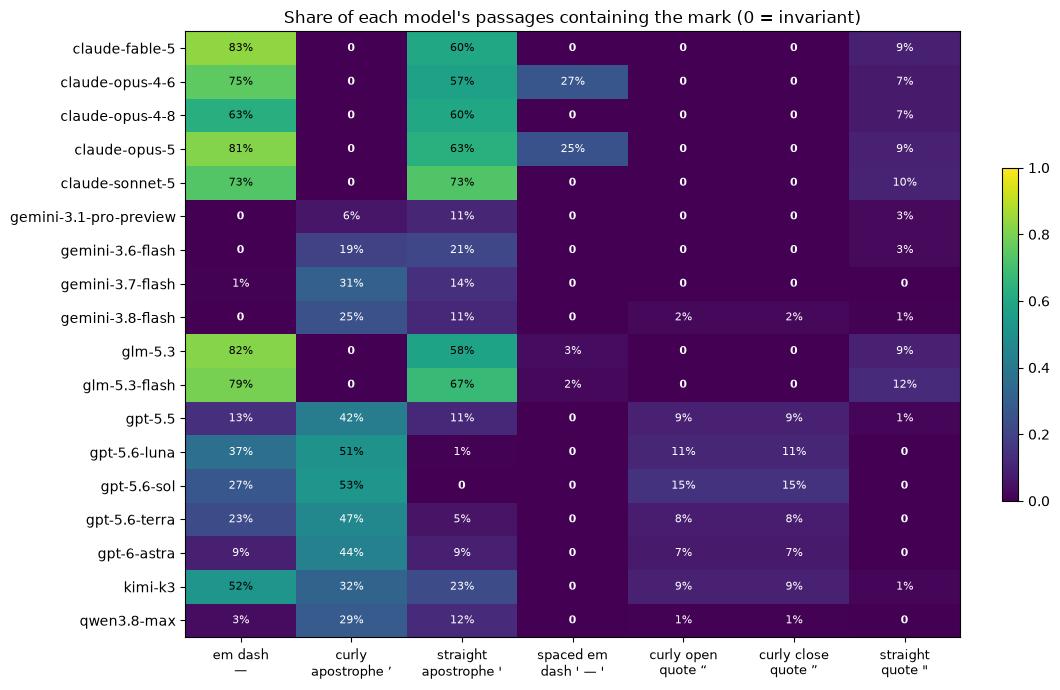

In [3]:
NAMES = {"—": "em dash\n—", "’": "curly\napostrophe ’", "'": "straight\napostrophe '",
         " — ": "spaced em\ndash ' — '", "“": "curly open\nquote “", "”": "curly close\nquote ”",
         '"': 'straight\nquote "'}
marks = [r["mark"] for r in RULES]
share = pd.DataFrame({NAMES.get(m, repr(m)): train.text.str.contains(m, regex=False)
                      .groupby(train.model).mean() for m in marks}).reindex(LABELS)
fig, ax = plt.subplots(figsize=(1.1 * len(marks) + 3, 7))
im = ax.imshow(share.values, cmap="viridis", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(marks)), share.columns, fontsize=9)
ax.set_yticks(range(len(LABELS)), LABELS)
for i in range(len(LABELS)):
    for j in range(len(marks)):
        v = share.values[i, j]
        ax.text(j, i, "0" if v == 0 else f"{v:.0%}", ha="center", va="center", fontsize=8,
                color="white" if v < 0.5 else "black", fontweight="bold" if v == 0 else None)
ax.set_title("Share of each model's passages containing the mark (0 = invariant)")
fig.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout()
plt.show()

## 2. Do the rules hold out of fold?

Mining and checking on the same 2,699 passages proves nothing. Test passages come from **unseen prompts**, so I split by `prompt_id` (GroupKFold, 5 folds), mine the rules on 4 folds and count violations on the held-out fold: a held-out passage that contains a mark although its true model is in the rule's *never* list.

In [4]:
from sklearn.model_selection import GroupKFold

folds = list(GroupKFold(5).split(train, train.model, groups=train.prompt_id))
rows, details = [], []
for k, (tr, va) in enumerate(folds):
    rules_k = mine_rules(train.text.iloc[tr], train.model.iloc[tr])
    va_text, va_model = train.text.iloc[va], train.model.iloc[va]
    hits = viol = 0
    for r in rules_k:
        has = va_text.str.contains(r["mark"], regex=False)
        bad = has & ~va_model.isin(r["allowed"])
        hits += int(has.sum())
        viol += int(bad.sum())
        for who in va_model[bad]:
            details.append(dict(fold=k, mark=repr(r["mark"]), true_model=who))
    rows.append(dict(fold=k, rules_mined=len(rules_k), rule_firings=hits, violations=viol))
print(pd.DataFrame(rows).to_string(index=False))
print("\nviolations:")
pd.DataFrame(details)

 fold  rules_mined  rule_firings  violations
    0            4           485           1
    1            6           524           0
    2            6           536           1
    3            6           566           2
    4            6           565           0

violations:


,fold,mark,true_model
0,0,'—',gemini-3.7-flash
1,2,"""'""",gpt-5.6-luna
2,3,'“',qwen3.8-max
3,3,'”',qwen3.8-max


So the rules are **near-invariants**, not laws: 4 held-out passages break them. Each one comes from a model that uses the mark *rarely* rather than never (e.g. `qwen3.8-max` writes curly quotes in 1 of its 150 train passages): when the fold holding that passage is dropped, the model looks like a "never" user. The rules mined on all of train already allow those models, but the same thing can happen on test with an even rarer habit. A hard mask turns each such case into a certain error, which is why the next section also tries soft penalties.

## 3. What they add, out of fold

A plain char/word TF-IDF + logistic regression gives out-of-fold probabilities. In each fold, the rules mined **only on the training folds** remove the forbidden models (−30 on their logits) for held-out passages. If several rules leave no model at all, the passage is left untouched.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import FeatureUnion, make_pipeline


def allowed_mask(texts, rules):
    mask = np.ones((len(texts), len(LABELS)), dtype=bool)
    for r in rules:
        col = np.isin(LABELS, list(r["allowed"]))
        hit = np.array([r["mark"] in t for t in texts])
        mask[hit] &= col
    mask[~mask.any(1)] = True
    return mask


def model():
    feats = FeatureUnion([
        ("char", TfidfVectorizer(analyzer="char", ngram_range=(3, 5), sublinear_tf=True,
                                 max_features=60000, lowercase=False)),
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, max_features=30000)),
    ])
    return make_pipeline(feats, LogisticRegression(C=4, max_iter=2000))


y = train.model.to_numpy()
L = np.zeros((len(train), len(LABELS)))
M = np.ones_like(L, dtype=bool)
for tr, va in folds:
    m = model().fit(train.text.iloc[tr], y[tr])
    L[va] = np.log(np.clip(m.predict_proba(train.text.iloc[va]), 1e-9, 1))
    M[va] = allowed_mask(train.text.iloc[va].tolist(),
                         mine_rules(train.text.iloc[tr], train.model.iloc[tr]))
labels = np.array(LABELS)
base = balanced_accuracy_score(y, labels[L.argmax(1)])
ruled = balanced_accuracy_score(y, labels[(L - 30 * ~M).argmax(1)])
changed = int((L.argmax(1) != (L - 30 * ~M).argmax(1)).sum())
print(f"out-of-fold balanced accuracy: {base:.4f} -> {ruled:.4f}  ({changed} predictions changed)")
print(f"passages touched by at least one rule: {(~M).any(1).mean():.0%}, "
      f"models still allowed on those: {M[(~M).any(1)].sum(1).mean():.1f} of 18")
sweep = {pen: balanced_accuracy_score(y, labels[(L - pen * ~M).argmax(1)])
         for pen in (0, 0.5, 1, 2, 4, 8, 30)}
pd.Series(sweep, name="OOF balanced accuracy").rename_axis("penalty on forbidden logits").round(4)

out-of-fold balanced accuracy: 0.3193 -> 0.3330  (119 predictions changed)
passages touched by at least one rule: 67%, models still allowed on those: 12.7 of 18


penalty on forbidden logits
0.0     0.3193
0.5     0.3326
1.0     0.3330
2.0     0.3330
4.0     0.3330
8.0     0.3330
30.0    0.3330
Name: OOF balanced accuracy, dtype: float64

Even on a TF-IDF model, whose character n-grams already "see" these marks, the rules mined out of fold add about a point of balanced accuracy, and the gain survives the few violations. The sweep shows how much of it needs a hard mask versus a soft penalty; a strong ensemble is confident more often, so a moderate penalty is the safer default there. The rules matter most where a model is **confident and wrong** on a forbidden class, which happens more in ensembles whose members are mostly semantic (embeddings, LLM heads).

## 4. Drop-in function

Paste this after your final logits (before `argmax`). It re-mines the rules on the official train at run time (so every rule has zero violations on train) and subtracts a penalty from the forbidden classes; pick the penalty from the sweep above or your own CV.

In [6]:
def apply_invariants(logits, test_texts, labels, train_texts, train_labels,
                     penalty=8.0, min_support=25, p_max=1e-4):
    """logits: (n, 18) in the order of `labels`. Returns new logits and #changed predictions."""
    global LABELS
    LABELS = list(labels)
    rules = mine_rules(train_texts, train_labels, min_support, p_max)
    for r in rules:  # safety: zero violations on train by construction; assert it anyway
        has = pd.Series(list(train_texts)).str.contains(r["mark"], regex=False).to_numpy()
        assert set(np.asarray(train_labels)[has]) <= r["allowed"]
    mask = allowed_mask([str(t) for t in test_texts], rules)
    out = np.asarray(logits, dtype=float) - penalty * ~mask
    return out, int((out.argmax(1) != np.asarray(logits).argmax(1)).sum())


# example on the public test sample (3 rows)
test = pd.read_csv(DATA / "test.csv")
demo = np.zeros((len(test), len(LABELS)))
_, n_changed = apply_invariants(demo, test.text, LABELS, train.text, train.model)
print("rules ready; demo ran on", len(test), "test rows")

rules ready; demo ran on 3 test rows


## Takeaways

- Formatting habits are **hard constraints** for some models: no dash, no curly quote, no straight apostrophe, ever.
- Out of fold on unseen prompts they are near-invariants: a few violations in ~2,700 firings (section 2), while touching about two thirds of passages.
- They still add about a point of out-of-fold balanced accuracy to a plain TF-IDF model (section 3).
- Caveat: 150 passages per model is a small sample; the test distribution differs between public and private LB. The P0 threshold and the run-time re-check keep the rules conservative.

If this was useful, an upvote helps others find it. Full code (grouped CV pitfalls, 4-view stylometric TF-IDF, Qwen3-Embedding features and LoRA): [https://github.com/pedrohbenetton/kaggle-name-that-llm](https://github.com/pedrohbenetton/kaggle-name-that-llm).